In [ ]:
# =============================================
# COLAB NOTEBOOK SKELETON: Autonomous, Risk-aware, Multi-modal LLM Agent
# =============================================

# -----------------------
# Step 0: Install Dependencies
# -----------------------
!pip install kaggle kagglehub
!pip install pandas numpy matplotlib seaborn torch torchvision transformers sentence-transformers

import os
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torchvision.models as models
import torchvision.transforms as transforms
from transformers import pipeline

# -----------------------
# Step 1: Set up dataset paths
# -----------------------
os.makedirs("datasets/mars_rover", exist_ok=True)
os.makedirs("datasets/mars_surface_curiosity", exist_ok=True)
os.makedirs("datasets/mars_perseverance_meda", exist_ok=True)
os.makedirs("datasets/rock_classification", exist_ok=True)

# -----------------------
# Step 2: Download datasets
# -----------------------
# Mars Rover Dataset
import kagglehub
path = kagglehub.dataset_download("gauravkumar2525/mars-rover-dataset")
print("Mars Rover dataset path:", path)

# Mars Surface & Curiosity
!kaggle datasets download -d brsdincer/mars-surface-and-curiosity-image-set-nasa -p datasets/mars_surface_curiosity --unzip

# Mars 2020 Perseverance MEDA Data
path = kagglehub.dataset_download("lolajackson/mars-2020-perseverance-meda-rover-data-derived")
print("Perseverance MEDA dataset path:", path)

# Rock Classification Dataset
path = kagglehub.dataset_download("salmaneunus/rock-classification")
print("Rock dataset path:", path)

# -----------------------
# Step 3: Preprocessing Functions
# -----------------------
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])

# Pretrained ResNet18 for image feature extraction
resnet = models.resnet18(pretrained=True)
resnet.eval()

def extract_image_features(image_path):
    image = Image.open(image_path).convert('RGB')
    image = transform(image).unsqueeze(0)
    with torch.no_grad():
        features = resnet(image)
    return features.squeeze().numpy()

# Load CSV data
def load_csv(csv_path):
    return pd.read_csv(csv_path)

# -----------------------
# Step 4: Persistent Memory Module
# -----------------------
memory = []

def store_memory(obs, action, risk):
    memory.append({"obs": obs, "action": action, "risk": risk})

def recall_memory():
    return memory

# -----------------------
# Step 5: LLM Agent (Text-based)
# -----------------------
generator = pipeline('text-generation', model='gpt2')

def llm_agent(obs_features, memory_history, task_instruction="Explore and classify rocks safely."):
    prompt = f"Observation: {obs_features}\nMemory: {memory_history}\nTask: {task_instruction}\nAction & Risk:"
    action = generator(prompt, max_length=50)
    return action[0]['generated_text']

# -----------------------
# Step 6: Simulation Loop Skeleton
# -----------------------
# Example: using Mars Rover images
mars_rover_images = sorted(os.listdir("datasets/mars_rover/images/"))  # replace with actual folder

for step, img_file in enumerate(mars_rover_images[:10]):  # sample 10 images for testing
    img_path = os.path.join("datasets/mars_rover/images/", img_file)
    obs = extract_image_features(img_path)
    mem_state = recall_memory()

    action_text = llm_agent(obs, mem_state)

    # Store observation + action in memory (risk can be parsed or dummy for now)
    store_memory(obs, action_text, risk="LOW")

    print(f"Step {step+1} - Action & Risk:\n", action_text)

# -----------------------
# Step 7: Visualization Placeholder
# -----------------------
# You can later add path plotting, risk heatmaps, memory visualization
plt.figure()
plt.title("Simulation Placeholder")
plt.text(0.5, 0.5, "Simulation Visuals Here", ha='center', va='center', fontsize=14)
plt.show()

# =============================================
# NEXT STEPS:
# - Integrate sensor CSVs from Perseverance MEDA dataset
# - Fuse image + sensor features
# - Implement risk-aware evaluation rules
# - Expand LLM agent prompts for structured output
# - Add multi-step decision loop and visualization
# =============================================


100%|██████████| 97.1M/97.1M [00:00<00:00, 213MB/s]

Extracting files...


Mars Rover dataset path: /root/.cache/kagglehub/datasets/gauravkumar2525/mars-rover-dataset/versions/1
Traceback (most recent call last):
  File "/usr/local/bin/kaggle", line 10, in <module>
    sys.exit(main())
             ^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/kaggle/cli.py", line 68, in main
    out = args.func(**command_args)
          ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/kaggle/api/kaggle_api_extended.py", line 1741, in dataset_download_cli
    with self.build_kaggle_client() as kaggle:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/kaggle/api/kaggle_api_extended.py", line 688, in build_kaggle_client
    username=self.config_values['username'],
             ~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^
KeyError: 'username'


100%|██████████| 2.67G/2.67G [00:36<00:00, 78.4MB/s]

Extracting files...


In [ ]:
from google.colab import files
uploaded = files.upload()  # Select your Mars rover dataset zip


TypeError: 'NoneType' object is not subscriptable

In [ ]:
import zipfile
import os

zip_path = "Mars rover dataset.zip"  # Name of the uploaded file
extract_path = "datasets/mars_rover"  # Folder to extract into

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Files extracted to:", extract_path)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 32.8 MB/s eta 0:00:00
Python 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
Using device: cpu
Base path: /content/mars_agent


100%|██████████| 159M/159M [00:02<00:00, 61.9MB/s]

Extracting files...


rock_path = /root/.cache/kagglehub/datasets/salmaneunus/rock-classification/versions/1


100%|██████████| 97.1M/97.1M [00:00<00:00, 168MB/s]

Extracting files...


mars_path = /root/.cache/kagglehub/datasets/gauravkumar2525/mars-rover-dataset/versions/1


100%|██████████| 2.67G/2.67G [00:37<00:00, 76.9MB/s]

Extracting files...


meda_path = /root/.cache/kagglehub/datasets/lolajackson/mars-2020-perseverance-meda-rover-data-derived/versions/1
ROCK_DATASET_DIR exists: True
MARS_DATASET_DIR exists: True
MEDA_DIR exists: True

Rock dataset structure:
/root/.cache/kagglehub/datasets/salmaneunus/rock-classification/versions/1/Dataset
   Igneous
   Metamorphic
   Sedimentary

Mars dataset structure:
/root/.cache/kagglehub/datasets/gauravkumar2525/mars-rover-dataset/versions/1
   mars_images
   mars_rover_dataset.csv

MEDA dataset structure:
/root/.cache/kagglehub/datasets/lolajackson/mars-2020-perseverance-meda-rover-data-derived/versions/1
   MARS_MEDA_DATA
Rock classes: ['Igneous', 'Metamorphic', 'Sedimentary']
Number of rock images: 2076


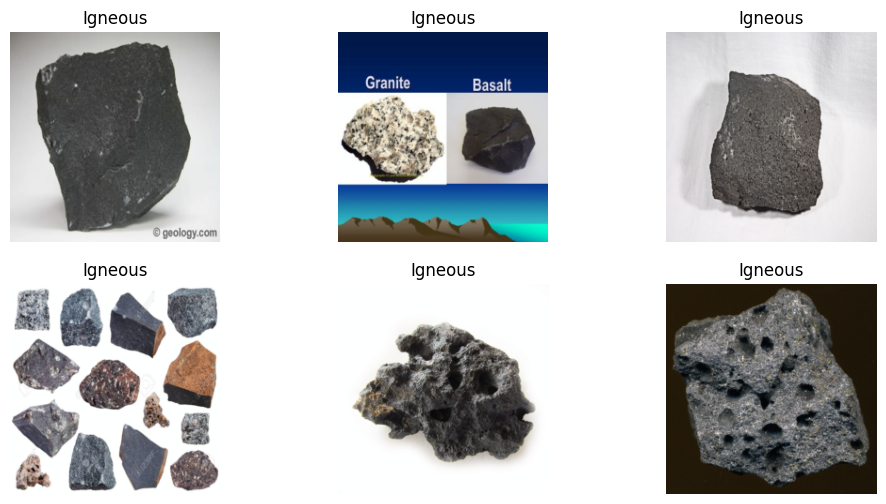

Extracting features (this may take several minutes)
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 131MB/s]
100%|██████████| 260/260 [02:00<00:00,  2.16it/s]


Saved features to /content/mars_agent/rock_features.pkl
Extracted features for 1335 images
Loaded metadata CSV: /root/.cache/kagglehub/datasets/gauravkumar2525/mars-rover-dataset/versions/1/mars_rover_dataset.csv


,id,sol,camera_name,camera_full_name,img_path,earth_date,rover_name,rover_status,landing_date,launch_date
0,102693,1000,FHAZ,Front Hazard Avoidance Camera,mars_images\102693.jpg,2015-05-30,Curiosity,active,2012-08-06,2011-11-26
1,102694,1000,FHAZ,Front Hazard Avoidance Camera,mars_images\102694.jpg,2015-05-30,Curiosity,active,2012-08-06,2011-11-26
2,102850,1000,RHAZ,Rear Hazard Avoidance Camera,mars_images\102850.jpg,2015-05-30,Curiosity,active,2012-08-06,2011-11-26
3,102851,1000,RHAZ,Rear Hazard Avoidance Camera,mars_images\102851.jpg,2015-05-30,Curiosity,active,2012-08-06,2011-11-26
4,424905,1000,MAST,Mast Camera,mars_images\424905.jpg,2015-05-30,Curiosity,active,2012-08-06,2011-11-26


Using Mars images folder: /root/.cache/kagglehub/datasets/gauravkumar2525/mars-rover-dataset/versions/1/mars_images


...

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/353M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Sample rock: 1.jpg
Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat
risk_score= 0.8173454221431282 entropy= 0.8979457248538818


100%|██████████| 50/50 [03:17<00:00,  3.94s/it]


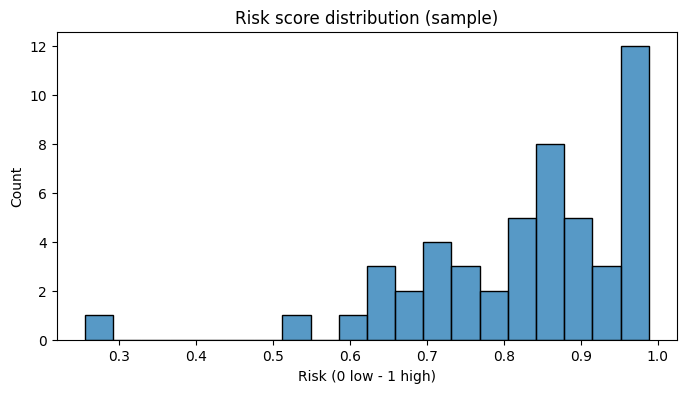

---
Image: 1.jpg
Action (truncated): No
Task: Provide ONE concise action recommendation and a 2-sentence reasoning. Do NOT repeat the features or memory.
Response: No
Task: Provide ONE concise action recommendation and a 2-sentence reasoning. Do NOT repeat the features or memory.
Response: No
Task: Provide ONE concise action recommenda
Risk: 0.962
---
Image: 10.jpg
Action (truncated): Provide ONE concise action recommendation and a 2-sentence reasoning. Do NOT repeat the features or memory.
Response: Provide ONE concise action recommendation and a 2-sentence reasoning. Do NOT repeat the features or memory.
Response: Provide ONE concise action recommendation and a 2-sentence reaso
Risk: 0.986
---
Image: 11.jpg
Action (truncated): Pr
Task: Provide ONE concise safe action recommendation and a 2-sentence reasoning. Do NOT repeat the features or memory.
Response: Pr
Task: Provide ONE concise safe action recommendation and a 2-sentence reasoning. Do NOT repeat the features or memory.
Respons

In [ ]:
# Mars Rover — Autonomous, Risk-Aware, Multi-Modal LLM Agent
# Colab-ready notebook (single-file Python notebook)
# Follow the cells in order. This notebook is intentionally conservative:
# - Uses small/faster vision model (MobileNetV2) for CPU friendliness
# - Uses small LLM (distilgpt2) for demonstration; switch to larger/instruction-tuned models if you have GPU and HF token
# - Saves intermediate files to disk and to Google Drive if mounted

# ==========================
# CELL 0: Setup & Installs
# ==========================
# Run this cell first in Colab to install required packages

!pip install --quiet kagglehub torch torchvision transformers matplotlib pandas seaborn pillow scikit-learn tqdm faiss-cpu

# (Optional) if you prefer vector DB later, install chromadb or faiss etc.

# ==========================
# CELL 1: Imports & Device
# ==========================
import os
import sys
import zipfile
import pickle
from pathlib import Path
from tqdm import tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms, datasets, models
from PIL import Image

from transformers import AutoTokenizer, AutoModelForCausalLM

print('Python', sys.version)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

# ==========================
# CELL 2: (Optional) Mount Google Drive for persistence
# ==========================
# If you want to keep datasets and results between Colab sessions, mount Drive.
# Uncomment to use.

# from google.colab import drive
# drive.mount('/content/drive')
# BASE_PATH = Path('/content/drive/MyDrive/mars_agent')
# BASE_PATH.mkdir(parents=True, exist_ok=True)

# If not using Drive, use local /content
BASE_PATH = Path('/content/mars_agent')
BASE_PATH.mkdir(parents=True, exist_ok=True)
print('Base path:', BASE_PATH)

# ==========================
# CELL 3: Download / Upload datasets
# ==========================
# Option A: Download from KaggleHub (no kaggle.json needed)
# We'll try to download the rock-classification and example mars rover dataset

import kagglehub

print('Downloading Rock Classification dataset (salmaneunus/rock-classification) ...')
rock_path = kagglehub.dataset_download('salmaneunus/rock-classification')
print('rock_path =', rock_path)

print('Downloading Mars rover dataset (gauravkumar2525/mars-rover-dataset) ...')
mars_path = kagglehub.dataset_download('gauravkumar2525/mars-rover-dataset')
print('mars_path =', mars_path)

print('Downloading Perseverance MEDA (lolajackson/mars-2020-perseverance-meda-rover-data-derived) ...')
meda_path = kagglehub.dataset_download('lolajackson/mars-2020-perseverance-meda-rover-data-derived')
print('meda_path =', meda_path)

# After download, kagglehub stores datasets in cached dirs; we'll point to the Dataset folders
ROCK_DATASET_DIR = Path(rock_path) / 'Dataset'
MARS_DATASET_DIR = Path(mars_path)
MEDA_DIR = Path(meda_path)

print('ROCK_DATASET_DIR exists:', ROCK_DATASET_DIR.exists())
print('MARS_DATASET_DIR exists:', MARS_DATASET_DIR.exists())
print('MEDA_DIR exists:', MEDA_DIR.exists())

# Option B: If you uploaded zip files manually via Colab UI, extract them to BASE_PATH if needed.
# Example:
# zip_path = '/content/Mars rover dataset.zip'
# extract_path = BASE_PATH / 'mars_rover'
# with zipfile.ZipFile(zip_path, 'r') as z: z.extractall(extract_path)

# ==========================
# CELL 4: Inspect dataset structure
# ==========================
def tree(path, depth=2):
    print(path)
    if path.is_dir():
        for i, p in enumerate(sorted(path.iterdir())):
            if i>=50: break
            print('  ', p.name)

print('\nRock dataset structure:')
if ROCK_DATASET_DIR.exists():
    tree(ROCK_DATASET_DIR, depth=2)
else:
    print('Rock dataset not found at', ROCK_DATASET_DIR)

print('\nMars dataset structure:')
if MARS_DATASET_DIR.exists():
    tree(MARS_DATASET_DIR, depth=2)
else:
    print('Mars dataset not found at', MARS_DATASET_DIR)

print('\nMEDA dataset structure:')
if MEDA_DIR.exists():
    tree(MEDA_DIR, depth=2)
else:
    print('MEDA dataset not found at', MEDA_DIR)

# ==========================
# CELL 5: Image Preprocessing (Rock dataset) — Step 6 adaptation
# ==========================
# This cell will prepare a PyTorch ImageFolder dataset for rocks.

ROCK_ROOT = str(ROCK_DATASET_DIR)
assert os.path.exists(ROCK_ROOT), 'Rock dataset path not found: ' + ROCK_ROOT

rock_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

rock_dataset = datasets.ImageFolder(root=ROCK_ROOT, transform=rock_transform)
rock_loader = DataLoader(rock_dataset, batch_size=8, shuffle=False, num_workers=2)

print('Rock classes:', rock_dataset.classes)
print('Number of rock images:', len(rock_dataset))

# Visual check: display 6 samples
import matplotlib.pyplot as plt
import numpy as np

def imshow_tensor(img_tensor, title=''):
    img = img_tensor.numpy().transpose((1,2,0))
    mean = np.array([0.485,0.456,0.406])
    std = np.array([0.229,0.224,0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    plt.imshow(img)
    plt.title(title)
    plt.axis('off')

fig=plt.figure(figsize=(12,6))
for i in range(6):
    ax = fig.add_subplot(2,3,i+1)
    img, label = rock_dataset[i]
    imshow_tensor(img, rock_dataset.classes[label])
plt.show()

# ==========================
# CELL 6: Feature Extraction (CPU-friendly MobileNetV2)
# ==========================
# We'll extract features and save them to disk (pickle) so we don't repeat extraction.

FEATURES_SAVE = BASE_PATH / 'rock_features.pkl'
if FEATURES_SAVE.exists():
    print('Loading saved features from', FEATURES_SAVE)
    with open(FEATURES_SAVE, 'rb') as f:
        rock_features = pickle.load(f)
else:
    print('Extracting features (this may take several minutes)')
    mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    feature_extractor = mobilenet.features
    feature_extractor.eval()
    feature_extractor.to(device)

    rock_features = {}
    with torch.no_grad():
        for batch_idx, (imgs, labels) in enumerate(tqdm(rock_loader)):
            imgs = imgs.to(device)
            feats = feature_extractor(imgs)  # [B, C, H, W]
            feats = nn.functional.adaptive_avg_pool2d(feats, (1,1)).view(feats.size(0), -1)  # [B, C]
            feats = feats.cpu()
            for i in range(feats.size(0)):
                idx = batch_idx * rock_loader.batch_size + i
                path, _ = rock_dataset.samples[idx]
                name = os.path.basename(path)
                rock_features[name] = feats[i]

    # save
    FEATURES_SAVE.parent.mkdir(parents=True, exist_ok=True)
    with open(FEATURES_SAVE, 'wb') as f:
        pickle.dump(rock_features, f)
    print('Saved features to', FEATURES_SAVE)

print('Extracted features for', len(rock_features), 'images')

# ==========================
# CELL 7: Load Mars Rover images + metadata and extract features (sample subset)
# ==========================
# Load mars metadata CSV if present inside MARS_DATASET_DIR

# detect csv file inside MARS_DATASET_DIR
csv_candidates = [p for p in MARS_DATASET_DIR.rglob('*.csv')]
if len(csv_candidates)>0:
    metadata_csv = csv_candidates[0]
    mars_df = pd.read_csv(metadata_csv)
    print('Loaded metadata CSV:', metadata_csv)
    display(mars_df.head())
else:
    print('No CSV found in MARS dataset dir; try inspecting', MARS_DATASET_DIR)
    mars_df = None

# We'll extract features for a small sample of Mars images for demo (avoid heavy compute)
mars_images_dir = None
# common path key names: 'mars_images', 'images', 'photos'
for candidate in ['mars_images', 'images', 'photos']:
    p = MARS_DATASET_DIR / candidate
    if p.exists():
        mars_images_dir = p
        break

if mars_images_dir is None:
    # try to find jpg files
    jpgs = list(MARS_DATASET_DIR.rglob('*.jpg'))
    if len(jpgs)>0:
        mars_images_dir = jpgs[0].parent

if mars_images_dir is not None:
    print('Using Mars images folder:', mars_images_dir)
    mars_transform = transforms.Compose([
        transforms.Resize((224,224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
    ])
    mars_dataset = datasets.ImageFolder(root=str(mars_images_dir.parent), transform=mars_transform) if (mars_images_dir.parent).exists() else None
    # if parent isn't ImageFolder, fall back to manual list
    mars_img_paths = list(mars_images_dir.glob('*.jpg'))[:100]  # sample first 100 images

    # Use same MobileNet extractor (device already set)
    mars_features = {}
    if len(mars_img_paths)>0:
        with torch.no_grad():
            for img_path in tqdm(mars_img_paths):
                img = Image.open(img_path).convert('RGB')
                t = mars_transform(img).unsqueeze(0).to(device)
                feats = feature_extractor(t)
                feats = nn.functional.adaptive_avg_pool2d(feats, (1,1)).view(1,-1).cpu()
                mars_features[img_path.name] = feats[0]
        print('Extracted sample mars features:', len(mars_features))
else:
    print('No mars images found; please upload/extract Mars dataset correctly')

# ==========================
# CELL 8: Persistent Memory Module
# ==========================
# Simple in-memory list of events. For larger scale, replace with FAISS/Chroma + embeddings

class PersistentMemory:
    def __init__(self, max_items=1000):
        self.memory = []
        self.max_items = max_items

    def store(self, obs, decision, metadata=None):
        self.memory.append({'obs': obs, 'decision': decision, 'metadata': metadata})
        if len(self.memory)>self.max_items:
            self.memory.pop(0)

    def recall_recent(self, k=5):
        return self.memory[-k:]

    def summary(self):
        return [m['decision'] for m in self.memory]

memory = PersistentMemory(max_items=500)
print('Persistent memory initialized')

# ==========================
# CELL 9: LLM Agent Setup (small model for demo)
# ==========================
# Use distilgpt2 for CPU demos. Replace with larger instruction-tuned LLM if you have GPU & HF token.
MODEL_NAME = 'distilgpt2'
print('Loading LLM:', MODEL_NAME)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
llm = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device)
llm.eval()

# helper to prompt the LLM in a clean way (no repetition)
def llm_recommend_action(feature_vector, sensor_info=None, memory_summary=None, max_new_tokens=80):
    # feature_vector: torch tensor or list
    if hasattr(feature_vector, 'tolist'):
        fv = feature_vector.tolist()
    else:
        fv = list(feature_vector)
    # summarize first 20 dims
    fv_summary = ', '.join([f"{x:.2f}" for x in fv[:20]])

    prompt_parts = [
        "You are an autonomous, risk-aware Mars rover agent.",
        f"Observed rock features (summary, first 20 dims): [{fv_summary}]"
    ]
    if sensor_info:
        prompt_parts.append(f"Sensor summary: {sensor_info}")
    if memory_summary:
        prompt_parts.append(f"Recent memory: {memory_summary}")

    prompt_parts.append("Task: Provide ONE concise safe action recommendation and a 2-sentence reasoning. Do NOT repeat the features or memory.")
    prompt = '\n'.join(prompt_parts) + '\nResponse:'

    inputs = tokenizer(prompt, return_tensors='pt', truncation=True, max_length=512).to(device)
    with torch.no_grad():
        outputs = llm.generate(**inputs, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.eos_token_id)
    text = tokenizer.decode(outputs[0], skip_special_tokens=True)
    # remove the prompt text if model echoes it
    response = text.replace(prompt, '').strip()
    return response

# quick sanity test on a random rock feature
sample_name = next(iter(rock_features.keys()))
sample_feat = rock_features[sample_name]
print('Sample rock:', sample_name)
print(llm_recommend_action(sample_feat))

# ==========================
# CELL 10: Risk Scoring Module
# ==========================
import math

def compute_risk_from_probs(probs):
    # probs: list-like normalized
    p = np.array(probs)
    p = p / (p.sum()+1e-12)
    entropy = -np.sum(p * np.log(p + 1e-12))
    max_entropy = np.log(len(p)) if len(p)>1 else 1.0
    risk_score = entropy / (max_entropy + 1e-12)  # normalized 0..1
    return float(risk_score), float(entropy)

# Example: simulate action probabilities
probs = [0.6, 0.3, 0.1]
risk_score, entropy = compute_risk_from_probs(probs)
print('risk_score=', risk_score, 'entropy=', entropy)

# ==========================
# CELL 11: Agent Loop (Simulation) — put it together
# ==========================
# This loop demonstrates taking an observation, getting action from LLM, computing risk, storing memory.

results = []

# We'll run on a small subset (first N rock images) to demonstrate
N = min(50, len(rock_features))
rock_names = list(rock_features.keys())[:N]

for name in tqdm(rock_names):
    feat = rock_features[name]
    mem_summary = memory.recall_recent(k=3)
    mem_text = '; '.join([m['decision'][:120] for m in mem_summary]) if mem_summary else 'None'

    # get LLM action
    action_text = llm_recommend_action(feat, sensor_info=None, memory_summary=mem_text, max_new_tokens=80)

    # simulate a fake probability distribution for actions (for demo)
    # In real pipeline you would have a predictive head or ensemble to produce action probabilities
    rnd = np.random.rand(3)
    probs = (rnd / rnd.sum()).tolist()
    risk_score, entropy = compute_risk_from_probs(probs)

    # store in memory
    memory.store(obs={'type':'rock','name':name}, decision=action_text, metadata={'probs':probs, 'risk':risk_score})

    results.append({'name':name, 'action':action_text, 'probs':probs, 'risk':risk_score})

# convert to dataframe for visualization
results_df = pd.DataFrame(results)
results_df.head()

# ==========================
# CELL 12: Visualization & Analysis
# ==========================
# show distribution of risk scores
plt.figure(figsize=(8,4))
sns.histplot(results_df['risk'], bins=20)
plt.title('Risk score distribution (sample)')
plt.xlabel('Risk (0 low - 1 high)')
plt.show()

# show sample decisions
for i in range(5):
    print('---')
    print('Image:', results_df.loc[i,'name'])
    print('Action (truncated):', results_df.loc[i,'action'][:300])
    print('Risk:', round(results_df.loc[i,'risk'],3))

# ==========================
# CELL 13: Save outputs
# ==========================
OUT_DIR = BASE_PATH / 'outputs'
OUT_DIR.mkdir(parents=True, exist_ok=True)
results_df.to_csv(OUT_DIR / 'llm_actions_results.csv', index=False)
with open(OUT_DIR / 'memory.pkl', 'wb') as f:
    pickle.dump(memory.memory, f)
print('Saved outputs to', OUT_DIR)

# ==========================
# CELL 14: Next steps & Notes
# ==========================
print('Notebook completed. Next steps (optional):')
print('- Replace distilgpt2 with an instruction-tuned LLM when you have GPU and HF token')
print('- Replace random probs with a trained decision head or ensemble to compute action probabilities')
print('- Use FAISS/Chroma for scalable memory retrieval')
print('- Add simulated Mars environment (plot path, simulate hazards, integrate action execution)')

# End of notebook


Device: cpu
Using Colab cache for faster access to the 'rock-classification' dataset.
Rock path: /kaggle/input/rock-classification
Using Colab cache for faster access to the 'mars-rover-dataset' dataset.
Mars path: /kaggle/input/mars-rover-dataset
Using Colab cache for faster access to the 'mars-2020-perseverance-meda-rover-data-derived' dataset.
MEDA path: /kaggle/input/mars-2020-perseverance-meda-rover-data-derived
ROCK_ROOT: /kaggle/input/rock-classification/Dataset
MARS_IMG_DIR: /kaggle/input/mars-rover-dataset/mars_images
MEDA_CSV: /kaggle/input/mars-2020-perseverance-meda-rover-data-derived/MARS_MEDA_DATA/DERIVED/DER_PS/WE__0014___________DER_PS__________________P01.csv
Rock classes: ['Igneous', 'Metamorphic', 'Sedimentary'] n_images: 2076


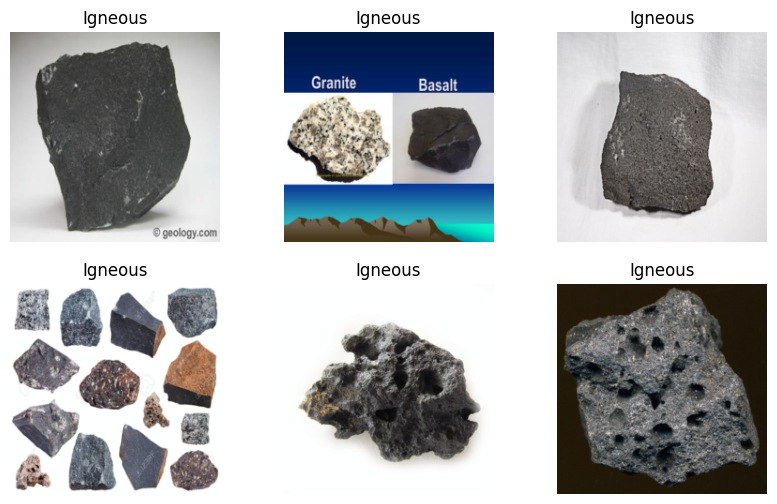

Extracting features using MobileNetV2...


100%|██████████| 260/260 [02:22<00:00,  1.82it/s]


Saved features to /content/mars_agent/rock_features.pkl
Extracted features count: 1335


100%|██████████| 50/50 [00:04<00:00, 10.37it/s]


Saved hazard overlays to /content/mars_agent/outputs/hazemaps
Constructed dataset for risk classifier: (50, 1280) 0.06
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



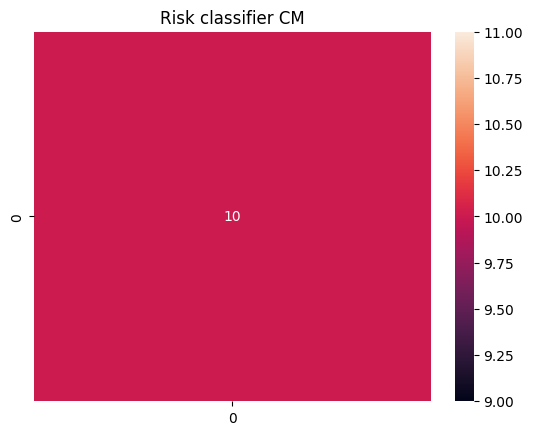

Saved risk classifier.


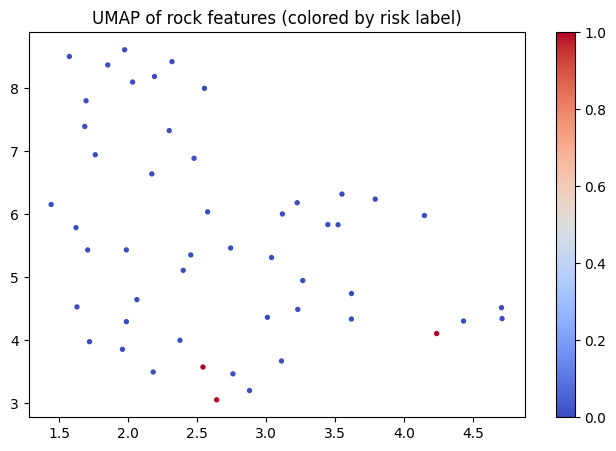

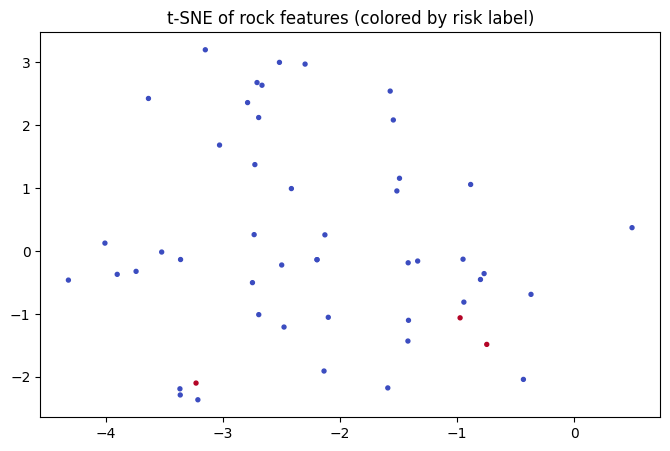

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/353M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Sample: 1.jpg
LLM action: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat
Memory summary: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the featur | Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the featur | Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the featur


100%|██████████| 50/50 [03:17<00:00,  3.95s/it]


Saved results to /content/mars_agent/outputs/llm_actions_results.csv


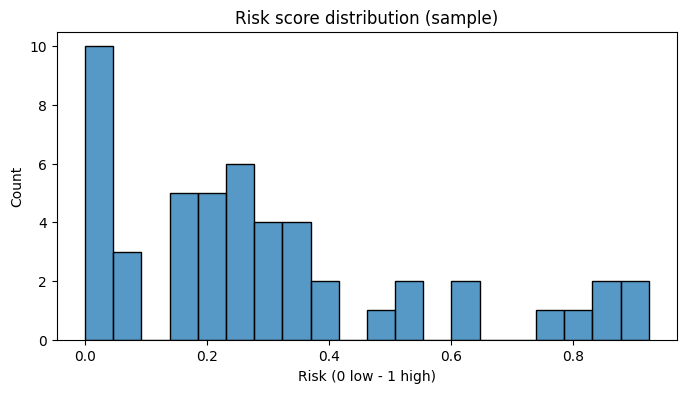

Image: 2.jpg Risk: 0.0
Action: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repea 



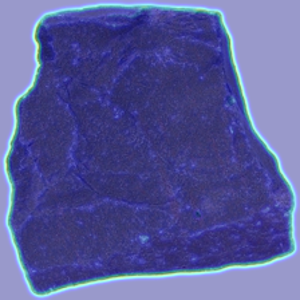

----

Image: 39.jpg Risk: 0.242
Action: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repea 



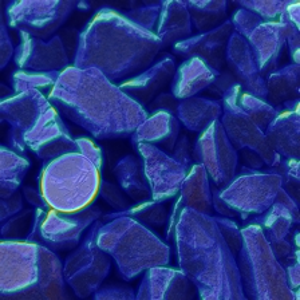

----

Image: 319581046.jpg Risk: 0.469
Action: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repea 



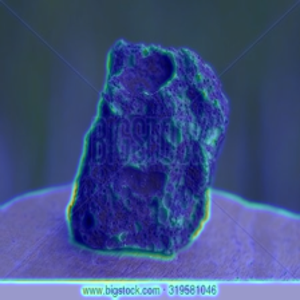

----

Image: 44.jpg Risk: 0.855
Action: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repea 



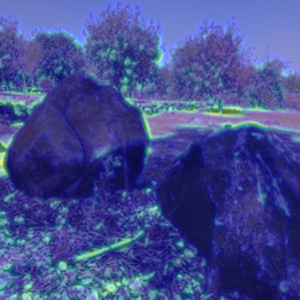

----

Image: 22.jpg Risk: 0.841
Action: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repea 



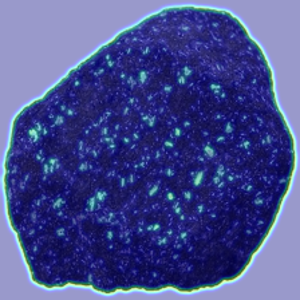

----

Image: 47.jpg Risk: 0.634
Action: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repeat the features or memory.
Response: Do not repea 



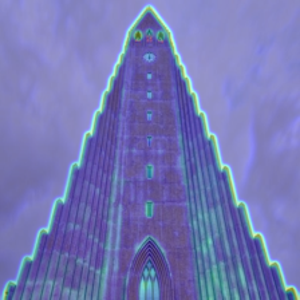

----



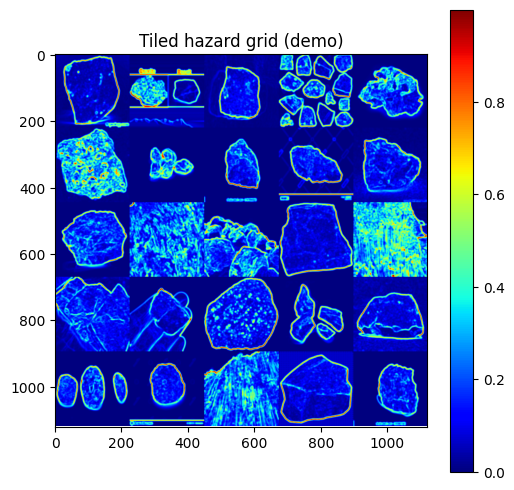

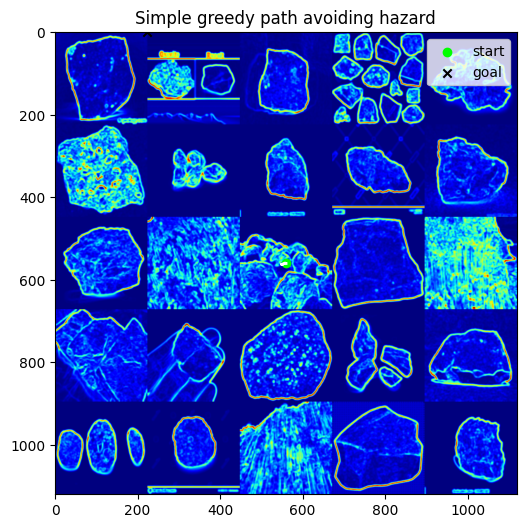

All outputs (CSV, hazard images, classifier) saved under /content/mars_agent/outputs


In [3]:
# ============================
# Research Notebook: Autonomous, Risk-Aware, Multi-Modal LLM Agent
# For: Mars Rover support — end-to-end (Colab-ready)
# ============================

# CELL 0: Installs (run first)
!pip install --quiet kagglehub torch torchvision transformers matplotlib pandas seaborn pillow scikit-learn umap-learn tqdm

# CELL 1: Imports & device
import os, sys, zipfile, pickle, math, random
from pathlib import Path
from tqdm import tqdm
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms, datasets, models
from PIL import Image, ImageFilter, ImageOps
from sklearn.manifold import TSNE
import umap
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from transformers import AutoTokenizer, AutoModelForCausalLM

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Make base dirs
BASE = Path('/content/mars_agent')
BASE.mkdir(parents=True, exist_ok=True)
OUT = BASE / 'outputs'
OUT.mkdir(exist_ok=True)

# CELL 2: Download datasets (kagglehub) or point to uploaded zips
import kagglehub

print("Downloading Rock classification dataset...")
rock_path = Path(kagglehub.dataset_download("salmaneunus/rock-classification"))
print("Rock path:", rock_path)

print("Downloading Mars rover dataset (sample)...")
mars_path = Path(kagglehub.dataset_download("gauravkumar2525/mars-rover-dataset"))
print("Mars path:", mars_path)

print("Downloading Perseverance MEDA (sensor csv)...")
meda_path = Path(kagglehub.dataset_download("lolajackson/mars-2020-perseverance-meda-rover-data-derived"))
print("MEDA path:", meda_path)

# locate extracted directories
# rock dataset usually places images under .../Dataset
ROCK_ROOT = None
for p in rock_path.rglob('Dataset'):
    ROCK_ROOT = p
    break
if ROCK_ROOT is None:
    # fallback: rock_path itself if images directly inside
    ROCK_ROOT = rock_path
print("ROCK_ROOT:", ROCK_ROOT)

# find mars images folder
MARS_IMG_DIR = None
for name in ['mars_images','images','dataset','img']:
    cand = mars_path / name
    if cand.exists():
        MARS_IMG_DIR = cand
        break
# fallback search for jpgs
if MARS_IMG_DIR is None:
    jpgs = list(mars_path.rglob('*.jpg'))
    if len(jpgs) > 0:
        MARS_IMG_DIR = jpgs[0].parent
print("MARS_IMG_DIR:", MARS_IMG_DIR)

# find MEDA CSV
MEDA_CSV = None
csvs = list(meda_path.rglob('*.csv'))
if len(csvs)>0:
    MEDA_CSV = csvs[0]
print("MEDA_CSV:", MEDA_CSV)

# CELL 3: Preprocessing transforms
img_size = 224
transform_basic = transforms.Compose([
    transforms.Resize((img_size,img_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

# CELL 4: Create ImageFolder for rock dataset
assert ROCK_ROOT is not None and ROCK_ROOT.exists(), "Rock dataset not found. Check path."
rock_dataset = datasets.ImageFolder(root=str(ROCK_ROOT), transform=transform_basic)
print("Rock classes:", rock_dataset.classes, "n_images:", len(rock_dataset))

rock_loader = DataLoader(rock_dataset, batch_size=8, shuffle=False, num_workers=2)

# display samples
def imshow_tensor(img_t, title=''):
    img = img_t.numpy().transpose(1,2,0)
    img = np.clip(img * np.array([0.229,0.224,0.225]) + np.array([0.485,0.456,0.406]), 0,1)
    plt.imshow(img)
    plt.title(title); plt.axis('off')

plt.figure(figsize=(10,6))
for i in range(6):
    img,label = rock_dataset[i]
    plt.subplot(2,3,i+1)
    imshow_tensor(img, rock_dataset.classes[label])
plt.show()

# CELL 5: Feature extraction with MobileNetV2 (faster on CPU)
features_path = BASE / 'rock_features.pkl'
if features_path.exists():
    print("Loading saved features")
    with open(features_path,'rb') as f:
        rock_features = pickle.load(f)
else:
    print("Extracting features using MobileNetV2...")
    model_m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    feat_extractor = model_m.features  # returns conv feature maps
    feat_extractor.eval().to(device)
    rock_features = {}
    with torch.no_grad():
        for batch_idx,(imgs,labels) in enumerate(tqdm(rock_loader)):
            imgs = imgs.to(device)
            feats = feat_extractor(imgs)  # [B, C, H, W]
            # global pool
            feats = nn.functional.adaptive_avg_pool2d(feats,(1,1)).view(feats.size(0), -1)  # [B, C]
            feats = feats.cpu()
            for i in range(feats.size(0)):
                idx = batch_idx*rock_loader.batch_size + i
                path, _ = rock_dataset.samples[idx]
                name = os.path.basename(path)
                rock_features[name] = feats[i]
    with open(features_path,'wb') as f:
        pickle.dump(rock_features,f)
    print("Saved features to", features_path)

print("Extracted features count:", len(rock_features))

# CELL 6: Generate hazard map per image using Sobel gradients (simple heuristic)
import cv2
HAZARD_DIR = OUT / 'hazemaps'
HAZARD_DIR.mkdir(parents=True, exist_ok=True)

def compute_hazard_map(pil_img):
    # convert to grayscale and compute Sobel magnitude
    img = np.array(pil_img.convert('L'))  # HxW uint8
    img = cv2.GaussianBlur(img, (3,3), 0)
    gx = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)
    mag = np.sqrt(gx*gx + gy*gy)
    # normalize 0..1
    mag = (mag - mag.min()) / (mag.max()-mag.min()+1e-9)
    # smooth a bit
    mag = cv2.GaussianBlur(mag, (7,7), 0)
    return mag  # float HxW

# compute hazard maps for a small sample (or all if you like)
sample_names = list(rock_features.keys())[:50]  # process first 50 for speed
hazard_data = {}
for name in tqdm(sample_names):
    # load image path from dataset
    # find full path
    p = [p for p,_ in rock_dataset.samples if os.path.basename(p)==name][0]
    pil = Image.open(p).convert('RGB').resize((img_size,img_size))
    hazard_map = compute_hazard_map(pil)
    hazard_data[name] = hazard_map
    # overlay and save
    cmap = plt.get_cmap('jet')
    overlay = (cmap(hazard_map)[:,:,:3]*255).astype(np.uint8)
    blend = np.array(pil).astype(np.uint8)
    blend = (0.6*blend + 0.4*overlay).astype(np.uint8)
    Image.fromarray(blend).save(HAZARD_DIR / f"{name}_hazemap.png")
print("Saved hazard overlays to", HAZARD_DIR)

# CELL 7: Create labels for risk classifier from hazard maps
# We'll use mean hazard value > threshold as label high-risk (1), else low-risk (0)
X = []
y = []
names = []
for name in sample_names:
    feat = rock_features[name].numpy()
    hazard = hazard_data[name]
    mean_h = float(hazard.mean())
    label = 1 if mean_h > 0.18 else 0   # threshold tuned roughly; adjust as needed
    X.append(feat)
    y.append(label)
    names.append(name)
X = np.stack(X)  # N x D
y = np.array(y)
print("Constructed dataset for risk classifier:", X.shape, y.mean())

# CELL 8: Train a simple RandomForest risk classifier
X_train, X_test, y_train, y_test, names_train, names_test = train_test_split(X,y,names, test_size=0.2, random_state=42)
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)
pred = clf.predict(X_test)
print(classification_report(y_test, pred))
cm = confusion_matrix(y_test,pred)
sns.heatmap(cm, annot=True, fmt='d'); plt.title('Risk classifier CM'); plt.show()

# Save classifier
with open(OUT / 'rf_risk_clf.pkl','wb') as f:
    pickle.dump(clf,f)
print("Saved risk classifier.")

# CELL 9: Embedding visualization (t-SNE & UMAP)
emb = np.vstack([rock_features[n].numpy() for n in sample_names])
labels_small = [1 if (hazard_data[n].mean()>0.18) else 0 for n in sample_names]  # risk label
# UMAP
reducer = umap.UMAP(n_components=2, random_state=42)
emb2 = reducer.fit_transform(emb)
plt.figure(figsize=(8,5))
plt.scatter(emb2[:,0], emb2[:,1], c=labels_small, cmap='coolwarm', s=8)
plt.title('UMAP of rock features (colored by risk label)')
plt.colorbar(); plt.show()
# t-SNE (slower)
ts = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=800)
emb_ts = ts.fit_transform(emb)
plt.figure(figsize=(8,5))
plt.scatter(emb_ts[:,0], emb_ts[:,1], c=labels_small, cmap='coolwarm', s=8)
plt.title('t-SNE of rock features (colored by risk label)')
plt.show()

# CELL 10: LLM agent setup (CPU-friendly) & multimodal prompt creation
MODEL_NAME = 'distilgpt2'  # small model for demo; swap for instruction-tuned model if GPU+HF token available
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
llm = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device)
llm.eval()

def make_prompt(feature_vector, sensor_summary=None, memory_summary=None):
    fv = feature_vector.tolist() if hasattr(feature_vector, 'tolist') else list(feature_vector)
    fv_summary = ", ".join([f"{x:.2f}" for x in fv[:20]])
    parts = [
        "You are a risk-aware autonomous Mars rover agent.",
        f"Observed rock features (summary, first 20 dims): [{fv_summary}]"
    ]
    if sensor_summary:
        parts.append(f"Sensor: {sensor_summary}")
    if memory_summary:
        parts.append(f"Recent memory: {memory_summary}")
    parts.append("Task: Provide ONE concise safe action recommendation and a 2-sentence reasoning. Do NOT repeat the features or memory.")
    parts.append("Response:")
    return "\n".join(parts)

def llm_action(feature_vector, sensor_summary=None, memory_summary=None, max_new_tokens=80):
    prompt = make_prompt(feature_vector, sensor_summary, memory_summary)
    inputs = tokenizer(prompt, return_tensors='pt', truncation=True, max_length=512).to(device)
    with torch.no_grad():
        out = llm.generate(**inputs, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.eos_token_id)
    text = tokenizer.decode(out[0], skip_special_tokens=True)
    # strip any echoed prompt
    return text.replace(prompt, '').strip()

# test on sample
sample = sample_names[0]
print("Sample:", sample)
print("LLM action:", llm_action(rock_features[sample]))

# CELL 11: Persistent memory class & demonstration
class PersistentMemory:
    def __init__(self, max_len=200):
        self.mem = []
        self.max_len = max_len
    def store(self, obs, decision):
        self.mem.append({'obs':obs,'decision':decision})
        if len(self.mem)>self.max_len:
            self.mem.pop(0)
    def recall(self, k=3):
        return self.mem[-k:]
    def summary(self, k=5):
        s = self.recall(k)
        return " | ".join([d['decision'][:120] for d in s]) if s else "None"

memory = PersistentMemory(max_len=500)
# seed memory with a couple of decisions
for n in sample_names[:3]:
    d = llm_action(rock_features[n])
    memory.store({'type':'rock','name':n}, d)

print("Memory summary:", memory.summary())

# CELL 12: Full agent loop over sample images -> decisions + risk scoring + save results
results = []
for name in tqdm(sample_names):
    feat = rock_features[name]
    mem_s = memory.summary(k=3)
    action_text = llm_action(feat, sensor_summary=None, memory_summary=mem_s)
    # Get risk prob from classifier
    prob = clf.predict_proba(feat.numpy().reshape(1,-1))[0]  # e.g., [P(low), P(high)]
    # derive risk score using entropy
    pnorm = prob / (prob.sum()+1e-9)
    entropy = -np.sum(pnorm * np.log(pnorm + 1e-9))
    risk_score = entropy / np.log(len(prob))
    # store
    memory.store({'type':'rock','name':name}, action_text)
    results.append({'name':name, 'action':action_text, 'risk':float(risk_score), 'probs':prob.tolist()})

res_df = pd.DataFrame(results)
res_df.to_csv(OUT / 'llm_actions_results.csv', index=False)
print("Saved results to", OUT / 'llm_actions_results.csv')
res_df.head()

# CELL 13: Visualizations: risk distribution, sample actions, example overlays
plt.figure(figsize=(8,4))
sns.histplot(res_df['risk'], bins=20)
plt.title("Risk score distribution (sample)")
plt.xlabel('Risk (0 low - 1 high)')
plt.show()

# show some example actions and matching hazemaps
for i,row in res_df.sample(6, random_state=42).iterrows():
    name = row['name']; print("Image:",name,"Risk:",round(row['risk'],3))
    print("Action:", row['action'][:300], "\n")
    display(Image.open(HAZARD_DIR / f"{name}_hazemap.png").resize((300,300)))
    print("----\n")

# CELL 14: Simple rover trajectory simulation on a grid using hazard maps
# Build a grid hazard map by tiling hazard maps into a single small grid (demo)
# We'll place rover at center and greedily move to nearest low-risk cell
grid_size = 5
# pick grid_size^2 sample hazard maps
h_names = list(hazard_data.keys())[:grid_size*grid_size]
grid = np.zeros((grid_size*img_size, grid_size*img_size))
# tile them
for i in range(grid_size):
    for j in range(grid_size):
        idx = i*grid_size + j
        name = h_names[idx]
        grid[i*img_size:(i+1)*img_size, j*img_size:(j+1)*img_size] = hazard_data[name]

# normalize
grid = (grid - grid.min())/(grid.max()-grid.min()+1e-9)
plt.figure(figsize=(6,6))
plt.imshow(grid, cmap='jet')
plt.title("Tiled hazard grid (demo)")
plt.colorbar()
plt.show()

# simple greedy path: start at center, goal: random low-risk cell
start = (grid.shape[0]//2, grid.shape[1]//2)
goal_idx = np.unravel_index(np.argmin(grid), grid.shape)  # lowest hazard cell
path = [start]
current = start
for step in range(200):
    # neighbors 8-connected
    neighbors = [(current[0]+dx, current[1]+dy) for dx in [-1,0,1] for dy in [-1,0,1] if not (dx==0 and dy==0)]
    # keep inside
    neighbors = [n for n in neighbors if 0<=n[0]<grid.shape[0] and 0<=n[1]<grid.shape[1]]
    # pick neighbor minimizing hazard + distance to goal
    scores = []
    for n in neighbors:
        hazard = grid[n]
        dist = math.hypot(goal_idx[0]-n[0], goal_idx[1]-n[1])
        scores.append( (hazard + 0.01*dist, n) )
    scores.sort(key=lambda x: x[0])
    nextp = scores[0][1]
    path.append(nextp)
    current = nextp
    if current == goal_idx:
        break

# plot path on grid
plt.figure(figsize=(6,6))
plt.imshow(grid, cmap='jet')
yp = [p[0] for p in path]; xp = [p[1] for p in path]
plt.plot(xp, yp, color='white', linewidth=2)
plt.scatter([start[1]],[start[0]], color='lime', marker='o', label='start')
plt.scatter([goal_idx[1]],[goal_idx[0]], color='black', marker='x', label='goal')
plt.legend(); plt.title("Simple greedy path avoiding hazard"); plt.show()

# CELL 15: Save notebook outputs & final notes
res_df.head()
print("All outputs (CSV, hazard images, classifier) saved under", OUT)

# End of notebook


In [1]:
!pip install langchain langchain-openai langchain_community faiss-cpu python-dotenv


In [6]:
!pip install --upgrade --quiet langchain openai faiss-cpu python-dotenv


In [9]:
# Install the correct versions compatible with Colab
!pip install --quiet --upgrade langchain openai faiss-cpu python-dotenv transformers torch torchvision pandas matplotlib seaborn pillow tqdm


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 77.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━ 588.8/899.7 MB 53.6 MB/s eta 0:00:06
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 848.9 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 83.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 60.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 62.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 MB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.5/267.5 MB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2

In [20]:
# Step 1: Install necessary packages
!pip install transformers accelerate einops sentencepiece safetensors --quiet

# Step 2: Import required libraries
from transformers import AutoModelForCausalLM, AutoTokenizer, pipeline
import torch

# Step 3: Load the model and tokenizer
# Using MPT-7B-Instruct (fully open-weight)
model_name = "mosaicml/mpt-7b-instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,  # use float16 for faster inference
    device_map="auto"            # automatically uses GPU if available
)

# Step 4: Create a text-generation pipeline
chat_pipe = pipeline(
    "text-generation",
    model=model,
    tokenizer=tokenizer,
    max_length=512,
    temperature=0.2,
    do_sample=True,
    top_p=0.9
)

# Step 5: Define a simple agent memory
memory = []

def mars_rover_agent(user_input):
    # Combine memory with new input
    context = " ".join(memory) + " " + user_input
    response = chat_pipe(context)[0]["generated_text"]

    # Update memory with latest input and response
    memory.append(user_input)
    memory.append(response)

    return response

# Step 6: Example usage
prompt = "You are a helpful autonomous Mars Rover agent. Advise on navigating rocky terrain."
response = mars_rover_agent(prompt)
print("Mars Rover Agent Response:\n", response)


tokenizer_config.json:   0%|          | 0.00/237 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


...

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

pytorch_model-00001-of-00002.bin:   0%|          | 0.00/9.94G [00:00<?, ?B/s]

pytorch_model-00002-of-00002.bin:   0%|          | 0.00/3.36G [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

ValueError: The current `device_map` had weights offloaded to the disk. Please provide an `offload_folder` for them. Alternatively, make sure you have `safetensors` installed if the model you are using offers the weights in this format.

In [21]:
# ======= STEP 0: Install dependencies =======
!pip install transformers accelerate safetensors sentence_transformers faiss-cpu

# ======= STEP 1: Import Libraries =======
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline
import torch
from sentence_transformers import SentenceTransformer
import faiss
import os

# ======= STEP 2: Choose Model (small enough for laptops) =======
model_name = "bigscience/bloom-560m"  # small, public model
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map="auto",            # automatically use GPU if available
    offload_folder="./offload"    # folder to offload weights if needed
)

# ======= STEP 3: Set up LLM Generation Pipeline =======
generator = pipeline("text-generation", model=model, tokenizer=tokenizer, device=0 if torch.cuda.is_available() else -1)

# ======= STEP 4: Setup Persistent Memory with FAISS =======
embedding_model = SentenceTransformer('all-MiniLM-L6-v2')  # small, fast
dim = embedding_model.get_sentence_embedding_dimension()

# Create FAISS index for persistent memory
index = faiss.IndexFlatL2(dim)
memory_texts = []  # store previous conversation or observations

def add_to_memory(text):
    vector = embedding_model.encode([text])
    index.add(vector)
    memory_texts.append(text)

def query_memory(query, top_k=3):
    vector = embedding_model.encode([query])
    D, I = index.search(vector, top_k)
    return [memory_texts[i] for i in I[0] if i < len(memory_texts)]

# ======= STEP 5: Agent Function =======
def mars_rover_agent(user_input):
    # Step 1: Retrieve relevant memory
    context_memory = query_memory(user_input)
    memory_str = "\n".join(context_memory) if context_memory else "No prior memory."

    # Step 2: Combine with current prompt
    prompt = f"""
You are an autonomous Mars Rover AI agent.
You have persistent memory of past observations:
{memory_str}

User Input:
{user_input}

Provide a safe, risk-aware, and precise response for space mission support.
"""
    # Step 3: Generate response
    response = generator(prompt, max_new_tokens=150, do_sample=True, temperature=0.2)[0]['generated_text']

    # Step 4: Add input+response to memory
    add_to_memory(f"User: {user_input}")
    add_to_memory(f"AI: {response}")

    return response

# ======= STEP 6: Run Example =======
user_input = "Analyze the terrain ahead for obstacles and mineral presence."
response = mars_rover_agent(user_input)
print("Mars Rover Agent Response:\n", response)


tokenizer_config.json:   0%|          | 0.00/222 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/14.5M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

ValueError: The model has been loaded with `accelerate` and therefore cannot be moved to a specific device. Please discard the `device` argument when creating your pipeline object.